# Clip and pansharpen RGB + pan GeoTIFFs with GDAL
Clip with `gdal.Warp`, then pansharpen with GDAL's built-in weighted Brovey (`gdal.CreatePansharpenedVRT`). Intermediates stay in memory (`/vsimem`).

In [7]:
from osgeo import gdal
import numpy as np
import matplotlib.pyplot as plt

gdal.UseExceptions()

RGB_PATH = "/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/WV02_20261005134656_B0300011013C6C10_26OCT05134656-M1BS-600000506581_01_P002_u08rf3031.tif"
PAN_PATH = "/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/WV02_20261005134656_B0300011013C6C10_26OCT05134656-P1BS-600000506581_01_P002_u08rf3031.tif"
OUT_PATH = "/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/pansharpened_WV02_20261005134656_B0300011013C6C10_26OCT05134656.tif"

# Clip AOI: a vector file OR a bbox (+ its CRS). Set both to None to skip clipping.
CLIP_VECTOR = None              # e.g. "aoi.gpkg"
CLIP_BBOX = [-2373085.2101596803,1222403.5487454252,-2368617.849366373,1226774.8372636077]                # (xmin, ymin, xmax, ymax)
CLIP_CRS = "EPSG:3031"          # CRS of CLIP_BBOX

WEIGHTS = (1/3, 1/3, 1/3)       # R,G,B weights for synthetic pan (Landsat 8/9: 0.45, 0.45, 0.10)
RESAMPLING = "Cubic"            # Nearest, Bilinear, Cubic, CubicSpline, Lanczos, Average
NODATA = 0

In [8]:
# Clip pan to the AOI (keeps its own CRS and resolution)
pan_opts = dict(format="GTiff", dstNodata=NODATA)
if CLIP_VECTOR:
    pan_opts.update(cutlineDSName=CLIP_VECTOR, cropToCutline=True)
elif CLIP_BBOX:
    pan_opts.update(outputBounds=CLIP_BBOX, outputBoundsSRS=CLIP_CRS)

pan_ds = gdal.Warp("/vsimem/pan_clip.tif", PAN_PATH, **pan_opts)

# Pan footprint and CRS
gt = pan_ds.GetGeoTransform()
xmin, ymax = gt[0], gt[3]
xmax = xmin + gt[1] * pan_ds.RasterXSize
ymin = ymax + gt[5] * pan_ds.RasterYSize
pan_wkt = pan_ds.GetProjection()

# Clip RGB to the pan footprint (reprojects to pan CRS if needed, keeps RGB resolution)
rgb_ds = gdal.Warp(
    "/vsimem/rgb_clip.tif", RGB_PATH,
    format="GTiff", dstSRS=pan_wkt,
    outputBounds=(xmin, ymin, xmax, ymax),
    resampleAlg="cubic", dstNodata=NODATA,
)

print("pan:", pan_ds.RasterXSize, "x", pan_ds.RasterYSize, "| rgb:", rgb_ds.RasterXSize, "x", rgb_ds.RasterYSize)

pan: 7203 x 7996 | rgb: 1848 x 2239


In [9]:
# Pansharpen
weights = ",".join(f"{w:.6f}" for w in WEIGHTS)
vrt_xml = f"""<VRTDataset subClass="VRTPansharpenedDataset">
  <PansharpeningOptions>
    <Algorithm>WeightedBrovey</Algorithm>
    <AlgorithmOptions><Weights>{weights}</Weights></AlgorithmOptions>
    <Resampling>{RESAMPLING}</Resampling>
    <NumThreads>ALL_CPUS</NumThreads>
    <NoData>{NODATA}</NoData>
    <SpectralBand dstBand="1"/>
    <SpectralBand dstBand="2"/>
    <SpectralBand dstBand="3"/>
  </PansharpeningOptions>
</VRTDataset>"""

spectral = [rgb_ds.GetRasterBand(i) for i in (1, 2, 3)]
vrt = gdal.CreatePansharpenedVRT(vrt_xml, pan_ds.GetRasterBand(1), spectral)

out_ds = gdal.Translate(
    OUT_PATH, vrt, format="GTiff",
    creationOptions=["COMPRESS=DEFLATE", "TILED=YES", "BIGTIFF=IF_SAFER"],
)
out_ds.FlushCache()
print("Wrote", OUT_PATH, out_ds.RasterXSize, "x", out_ds.RasterYSize)

Wrote /Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/pansharpened_WV02_20261005134656_B0300011013C6C10_26OCT05134656.tif 7203 x 7996


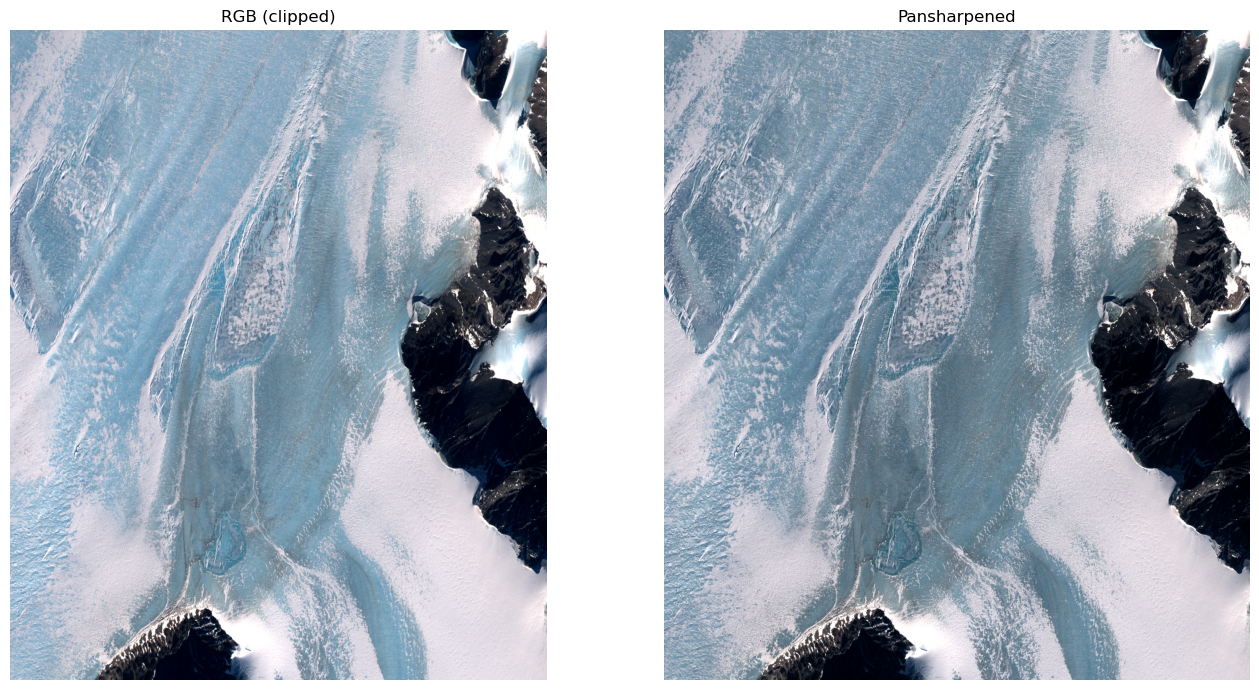

In [10]:
# Quick look: clipped RGB vs pansharpened (2-98% stretch, downsampled for display)
def show(ds, ax, title, max_px=1500):
    step = max(1, max(ds.RasterXSize, ds.RasterYSize) // max_px)
    w, h = ds.RasterXSize // step, ds.RasterYSize // step
    arr = ds.ReadAsArray(buf_xsize=w, buf_ysize=h, band_list=[1, 2, 3]).astype("float32")
    arr = np.moveaxis(arr, 0, -1)
    valid = arr[arr.sum(-1) > 0]
    lo, hi = np.percentile(valid, (2, 98)) if valid.size else (0, 1)
    ax.imshow(np.clip((arr - lo) / (hi - lo), 0, 1))
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
show(rgb_ds, axes[0], "RGB (clipped)")
show(out_ds, axes[1], "Pansharpened")
plt.tight_layout()

In [11]:
# Smaller copy for sharing
SHARE_PATH = "/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/pansharpened_share_WV02_20261005134656_B0300011013C6C10_26OCT05134656.tif"
SHARE_FACTOR = 2        # 2 = half the resolution (pixel size x2, ~1/4 the pixels)
TO_8BIT = True          # stretch to 8-bit + JPEG compression (much smaller); False keeps values, DEFLATE

pct = 100 / SHARE_FACTOR
opts = dict(
    format="GTiff",
    widthPct=pct, heightPct=pct,
    resampleAlg="average",          # avoids aliasing when downsampling
)

if TO_8BIT:
    # 2-98% stretch per band, estimated from a decimated read
    step = max(1, max(out_ds.RasterXSize, out_ds.RasterYSize) // 2000)
    arr = out_ds.ReadAsArray(buf_xsize=out_ds.RasterXSize // step,
                             buf_ysize=out_ds.RasterYSize // step).astype("float32")
    scale = []
    for b in arr:
        v = b[b != NODATA]
        lo, hi = np.percentile(v, (2, 98)) if v.size else (0, 1)
        scale.append([float(lo), float(hi), 1, 255])   # keep 0 for nodata
    opts.update(
        outputType=gdal.GDT_Byte, scaleParams=scale, noData=0,
        creationOptions=["COMPRESS=JPEG", "JPEG_QUALITY=85", "PHOTOMETRIC=YCBCR", "TILED=YES"],
    )
else:
    opts.update(creationOptions=["COMPRESS=DEFLATE", "PREDICTOR=2", "TILED=YES"])

share_ds = gdal.Translate(SHARE_PATH, OUT_PATH, **opts)
share_ds.BuildOverviews("AVERAGE", [2, 4, 8, 16])   # quick zooming in QGIS etc.
share_ds = None

import os
mb = lambda p: os.path.getsize(p) / 1e6
print(f"{OUT_PATH}: {mb(OUT_PATH):.1f} MB  ->  {SHARE_PATH}: {mb(SHARE_PATH):.1f} MB")

/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/pansharpened_WV02_20261005134656_B0300011013C6C10_26OCT05134656.tif: 109.8 MB  ->  /Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/remote sensing/worldview/fridge_1493_jkingslake/ortho/pansharpened_share_WV02_20261005134656_B0300011013C6C10_26OCT05134656.tif: 5.1 MB


In [5]:
# Clean up
vrt = out_ds = pan_ds = rgb_ds = spectral = None
gdal.Unlink("/vsimem/pan_clip.tif")
gdal.Unlink("/vsimem/rgb_clip.tif")

0